## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import pandas as pd
import fastparquet
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_parquet(
    "./data/ff_market_daily.parquet",
    engine="fastparquet"
)

In [3]:
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

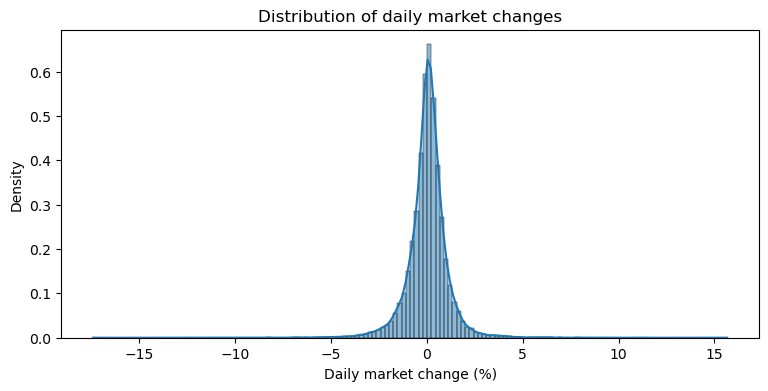

In [4]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

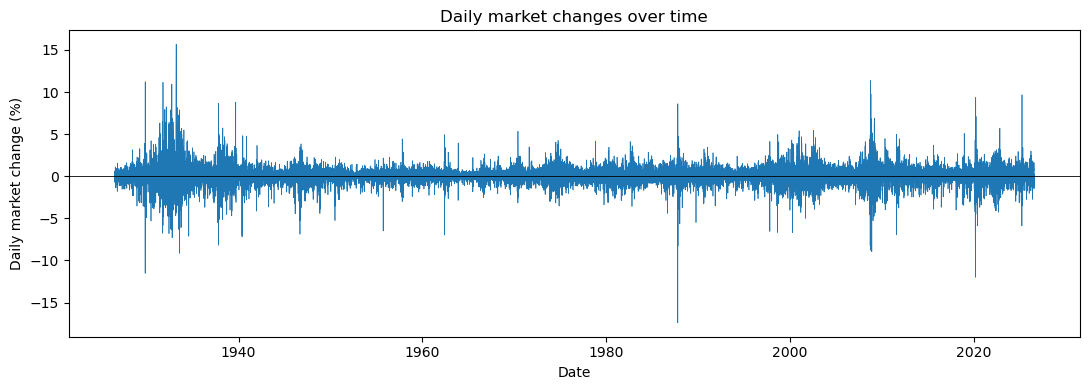

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.

In [6]:
df['state'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down (and flat)')
df['y_t'] = df['state']
df['y_tp1'] = df['state'].shift(-1)

In [7]:
print(df[['date', 'market_return_pct', 'y_t', 'y_tp1']].head())

        date  market_return_pct y_t            y_tp1
0 1926-07-01               0.10  Up               Up
1 1926-07-02               0.46  Up               Up
2 1926-07-06               0.18  Up               Up
3 1926-07-07               0.10  Up               Up
4 1926-07-08               0.23  Up  Down (and flat)


- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 

In [8]:
counts_table = pd.crosstab(df['y_t'], df['y_tp1'])
print("Raw Transition Counts") 
print(counts_table)

Raw Transition Counts
y_tp1            Down (and flat)    Up
y_t                                   
Down (and flat)             5909  5999
Up                          5999  8388


In [9]:
joint_pmf_with_marginals = pd.crosstab( df['y_t'], df['y_tp1'], normalize=True, margins=True ) 
print("\nJoint PMF with Marginal Distributions") 
print(joint_pmf_with_marginals)


Joint PMF with Marginal Distributions
y_tp1            Down (and flat)        Up       All
y_t                                                 
Down (and flat)         0.224720  0.228142  0.452862
Up                      0.228142  0.318996  0.547138
All                     0.452862  0.547138  1.000000


In [10]:
conditional_pmf = pd.crosstab( 
    df['y_t'], 
    df['y_tp1'], 
    normalize='index' 
    ) 
print("\nConditional PMF") 
print(conditional_pmf)


Conditional PMF
y_tp1            Down (and flat)        Up
y_t                                       
Down (and flat)         0.496221  0.503779
Up                      0.416974  0.583026


- Are up transitions more or less common than down transitions? 

Up transitions are more common than down transitions. According to our Joint PMF table, the market state for the next day is "Up" 54.71% of the time, and "Down" 45.29% of the time. 

- Are you more likely to transition to an Up day from a Down or Up day?

As seen by the Conditional PMF table, you are more likely to transition to an Up day from another "Up" day (with 58.30% probability) than from a "Down" day (50.38% probability).

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?

In [11]:
bins = [-np.inf, -1.0, -0.1, 0.1, 1.0, np.inf]
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']

In [12]:
df['state_5'] = pd.cut( df['market_return_pct'], bins=bins, labels=labels, right=True )

In [13]:
bin_counts = df['state_5'].value_counts() 
print(bin_counts)

state_5
Small gain    9785
Small loss    7452
Near zero     3441
Large gain    2859
Large loss    2759
Name: count, dtype: int64


According to the frequency data frame of our five states, the most common bin is a "small gain" at 9785 counts, and the least common bin is a "large loss" at 2759 counts. 

- Compute the joint PMF and marginals. Which transitions are most likely to occur? 

In [14]:
df['y_t'] = df['state_5'] 
df['y_tp1'] = df['state_5'].shift(-1)

In [15]:
joint_pmf_states = pd.crosstab( df['y_t'], df['y_tp1'], normalize=True, margins=True )

In [16]:
print("Joint PMF with Marginal Distribution") 
print(joint_pmf_states)

Joint PMF with Marginal Distribution
y_tp1       Large loss  Small loss  Near zero  Small gain  Large gain  \
y_t                                                                     
Large loss    0.021335    0.027191   0.009051    0.027800    0.019547   
Small loss    0.035444    0.088648   0.034151    0.097775    0.027382   
Near zero     0.009317    0.041985   0.020955    0.049325    0.009279   
Small gain    0.024986    0.100057   0.055029    0.159422    0.032592   
Large gain    0.013843    0.025518   0.011637    0.037802    0.019928   
All           0.104925    0.283400   0.130823    0.372124    0.108728   

y_tp1            All  
y_t                   
Large loss  0.104925  
Small loss  0.283400  
Near zero   0.130861  
Small gain  0.372086  
Large gain  0.108728  
All         1.000000  


According to our Joint PMF table, the most common transition between days is a small gain transitioning to another small gain, accounting for 15.9422% of all transitions. 

- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?

In [17]:
conditional_pmf_states = pd.crosstab( df['y_t'], df['y_tp1'], normalize='index' ) 
print("Conditional PMF") 
print(conditional_pmf_states)

Conditional PMF
y_tp1       Large loss  Small loss  Near zero  Small gain  Large gain
y_t                                                                  
Large loss    0.203335    0.259152   0.086263    0.264951    0.186299
Small loss    0.125067    0.312802   0.120505    0.345008    0.096618
Near zero     0.071200    0.320837   0.160128    0.376925    0.070910
Small gain    0.067150    0.268908   0.147895    0.428455    0.087592
Large gain    0.127317    0.234697   0.107030    0.347674    0.183281


Across every current state, the top two predicted future states are a "Small gain" and a "Small loss".

A uniform mass function across five states would assign a equal probability of 0.20 to every cell. Our large loss row is the closest to uniform, since cells such as 'Large loss' at 0.203 probability, 'Large gain' at 0.186, 'Small loss' at 0.259, and 'Small gain' at 0.265 are closest to 0.20. 

In the "Small loss", "Near zero", and "Large gain" rows, the probability mass is heavily concentrated in cells 'Small gain' and 'Small loss', while extreme cells such as 'Large loss' and 'Large gain' have low probability mass.

The "Small gain" row is the furthest from uniform. It contains the highest probability mass for a single cell with 'Small gain' at 0.428, while the extreme state probabilities, 'Large loss' at 0.067 and 'Large gain' at 0.088, have extremely low probability mass.

In my opinion, it is relatively difficult to predict the next market state with high accuracy based on today's state alone. Because 'Small gain' and 'Small loss' are the top two outcomes across ALL rows, the conditional distributions heavily reflect the overall unconditional marginal distribution of daily returns. Knowing today's state offers very little extra predictive value.

- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [18]:
df['market_return_tp1'] = df['market_return_pct'].shift(-1)
conditional_stats = df.groupby('y_t', observed=False)['market_return_tp1'].describe()
print("Returns Conditionals Summary")
print(conditional_stats[['count', 'mean', 'std', 'min', 'max']])

Returns Conditionals Summary
             count      mean       std    min    max
y_t                                                 
Large loss  2759.0 -0.038311  1.720570 -17.41  11.22
Small loss  7452.0 -0.043814  1.009529 -11.23  11.36
Near zero   3441.0  0.015013  0.826054  -8.19   5.49
Small gain  9784.0  0.106810  0.832186  -8.25   8.67
Large gain  2859.0  0.163092  1.384086 -12.00  15.67


When today is a "Loss day" ('Large loss' or 'Small loss'), tomorrow’s expected return is negative (around -0.038% to -0.044%). When today is a "Gain day" ('Small gain' or 'Large gain'), tomorrow’s expected return is noticeable positive.

The largest standard deviation is at "Large loss" with 1.72%, which measures the conditional volatility for tomorrow. "High-magnitude" moves today (such as a 'Large loss' at 1.72% and 'Large gain' at 1.38%) lead to high volatility tomorrow. Low-magnitude moves today (such as 'Near zero' and 'Small gain' at 0.83%) lead to low volatility tomorrow.

The minimum and maximum returns for tomorrow expand dramatically during extreme starting states. The worst market crash day in the dataset (-17.41%) occurs immediately following a 'Large loss' day. Conversely, the largest surge in the dataset (15.67%) occurs immediately following a 'Large gain' day. Days following 'Near zero' or 'Small gain' have value ranges of 13.68% and 16.92%, respectively.

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`.

In [19]:
df['bin_21'] = pd.qcut(df['market_return_pct'], q=21, labels=False)

In [20]:
df['y_t'] = df['bin_21']
df['y_tp1'] = df['bin_21'].shift(-1)

In [21]:
print(df[['date', 'market_return_pct', 'y_t', 'y_tp1']].head())

        date  market_return_pct  y_t  y_tp1
0 1926-07-01               0.10   10   15.0
1 1926-07-02               0.46   15   11.0
2 1926-07-06               0.18   11   10.0
3 1926-07-07               0.10   10   12.0
4 1926-07-08               0.23   12    3.0


- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.

In [22]:
joint_pmf_21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize=True)
joint_pmf_diff = joint_pmf_21 - (1.0 / (21**2)) #normalizing away the uniform PMF

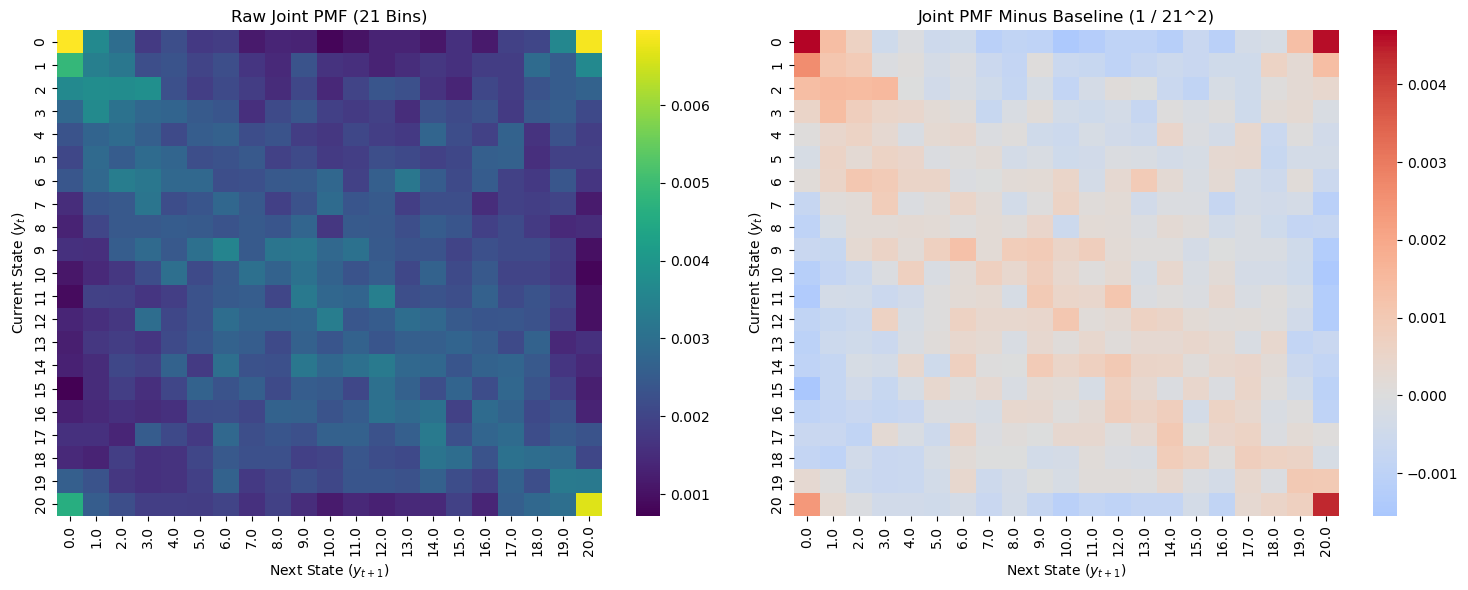

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.heatmap(joint_pmf_21, cmap='viridis', ax=axes[0])
axes[0].set_title('Raw Joint PMF (21 Bins)')
axes[0].set_xlabel('Next State ($y_{t+1}$)')
axes[0].set_ylabel('Current State ($y_t$)')

sns.heatmap(joint_pmf_diff, cmap='coolwarm', center=0, ax=axes[1])
axes[1].set_title('Joint PMF Minus Baseline (1 / 21^2)')
axes[1].set_xlabel('Next State ($y_{t+1}$)')
axes[1].set_ylabel('Current State ($y_t$)')
plt.tight_layout()
plt.show()

Since we have created 21 bins, the joint transition table contains 21 * 21 = 441 cells.

If transitions were completely independent and uniformly distributed across quantiles, every cell in the Joint PMF would equal 1/441, or 0.0027. Subtracting the baseline in the right heatmap highlights positive deviations (transitions occurring more frequently than random chance) in "warm" shades, and negative deviations in  the "cool" shades.

- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.

In [24]:
cond_pmf_21 = pd.crosstab(df['y_t'], df['y_tp1'], normalize='index')
cond_pmf_diff = cond_pmf_21 - (1.0 / 21) #normalizing away the uniform PMF

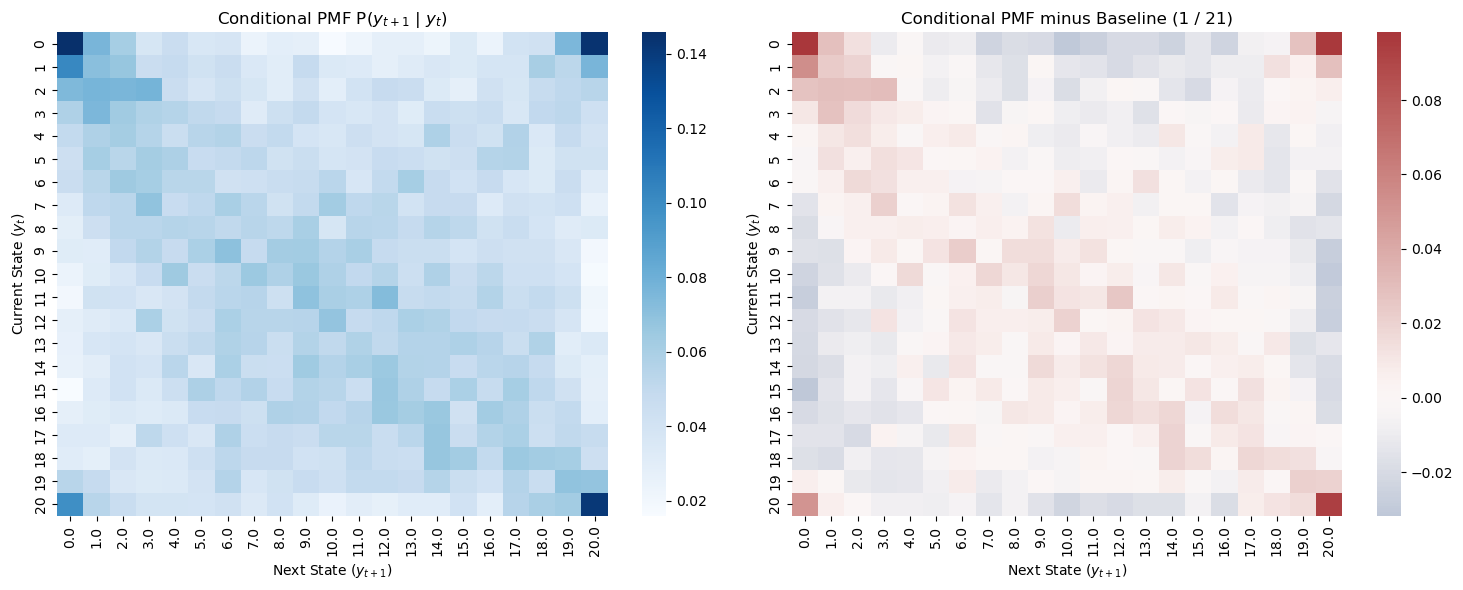

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.heatmap(cond_pmf_21, cmap='Blues', ax=axes[0])
axes[0].set_title('Conditional PMF P($y_{t+1}$ | $y_t$)')
axes[0].set_xlabel('Next State ($y_{t+1}$)')
axes[0].set_ylabel('Current State ($y_t$)')

sns.heatmap(cond_pmf_diff, cmap='vlag', center=0, ax=axes[1])
axes[1].set_title('Conditional PMF minus Baseline (1 / 21)')
axes[1].set_xlabel('Next State ($y_{t+1}$)')
axes[1].set_ylabel('Current State ($y_t$)')

plt.tight_layout() 
plt.show()

Since each row in a conditional PMF table sums to 1, under a uniform baseline, each row would spread probability near evenly across all 21 future states at roughly 4.76% per cell. Subtracting the baseline shows how conditioning on today's quantile alters tomorrow's likelihood in comparison to the uniform base rate.

- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 

In [26]:
stats_21 = df.groupby('y_t', observed=False)['market_return_tp1'].agg(['min', 'mean', 'max', 'std'])
print(stats_21)

       min      mean    max       std
y_t                                  
0   -17.41 -0.013713  11.22  2.140465
1    -7.36 -0.076712   6.36  1.285882
2    -8.79 -0.097084  11.36  1.227976
3    -8.28 -0.058594   6.16  1.049607
4    -6.89 -0.024211   4.56  0.989470
5   -11.23 -0.022692   6.37  1.024761
6    -3.94 -0.030241   7.37  0.930389
7    -3.40 -0.014303   4.76  0.835663
8    -6.00  0.025860   5.49  0.853220
9    -8.19 -0.012998   3.60  0.811559
10   -7.30  0.034694   4.69  0.805212
11   -8.25  0.091930   7.88  0.791857
12   -6.82  0.056646   5.66  0.784100
13   -5.12  0.087555   4.16  0.816509
14   -6.49  0.091397   5.70  0.831233
15   -6.99  0.126421   8.67  0.789961
16   -7.13  0.125838   4.84  0.826667
17   -6.30  0.130062   8.60  0.959673
18   -8.96  0.175192   4.38  0.900844
19   -4.93  0.132760   6.04  1.099897
20  -12.00  0.195113  15.67  1.702623


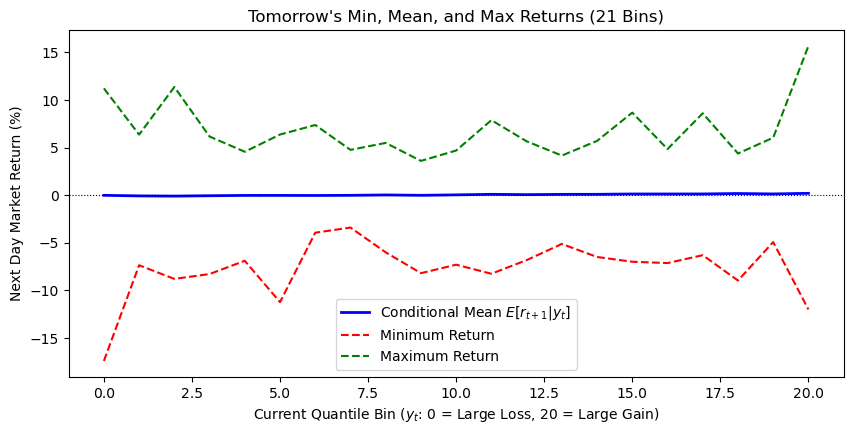

In [27]:
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(stats_21.index, stats_21['mean'], label='Conditional Mean $E[r_{t+1}|y_t]$', color='blue', linewidth=2)
ax.plot(stats_21.index, stats_21['min'], label='Minimum Return', color='red', linestyle='--')
ax.plot(stats_21.index, stats_21['max'], label='Maximum Return', color='green', linestyle='--')
ax.axhline(0, color='black', linewidth=0.8, linestyle=':')
ax.set_xlabel('Current Quantile Bin ($y_t$: 0 = Large Loss, 20 = Large Gain)')
ax.set_ylabel('Next Day Market Return (%)')
ax.set_title("Tomorrow's Min, Mean, and Max Returns (21 Bins)")
ax.legend()
plt.show()

The expected return line is flat and lies almost directly on the 0% reference line across all 21 bins. This means that whether or not today's market return fell into an extreme loss quantile (Bin 0) or an extreme gain quantile (Bin 20), tomorrow's expected return remains near 0%.

In contrast to the flat mean, the minimum and maximum values form a wide range around the mean. In the middle bins, 7–13, the distance between the minimum and maximum returns is narrowest, with minimums around -4% to -5% and maximums around 4% to 6%. In the outer bins, 0 and 20, the range widens dramatically. Following an extreme loss day (Bin 0), tomorrow's minimum drops to -17.4%, while its maximum reaches 11.2%. Following an extreme gain day (Bin 20), tomorrow's minimum drops to -12.0%, while its maximum reaches 15.5%. The minimum and maximum values show that extreme market movements today open up a significantly wider spectrum of potential outcomes, both positive and negative, for the next day.

- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 

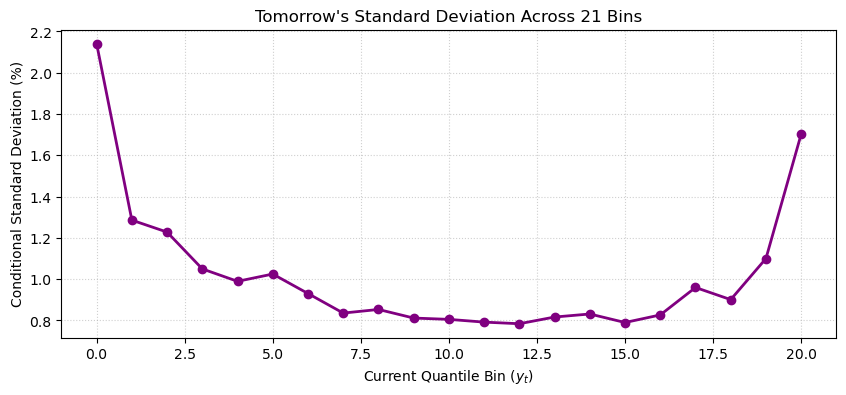

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(stats_21.index, stats_21['std'], color='purple', marker='o', linewidth=2)
ax.set_xlabel('Current Quantile Bin ($y_t$)')
ax.set_ylabel('Conditional Standard Deviation (%)')
ax.set_title("Tomorrow's Standard Deviation Across 21 Bins")
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()

The standard deviation curve shows a "U-shape" across the 21 quantile bins. In the central bins 7–15, which represent "moderate" market days, the conditional standard deviation reaches its lowest levels at about 0.78% to 0.85%. At the outer quantiles, the standard deviation increases rapidly, reaching about 1.70% for Bin 20 (an extreme gain) and peaking at 2.14% for Bin 0 (an extreme loss). This U-shape shows that high-magnitude price movements today, regardless of direction, lead to higher conditional dispersion and uncertainty tomorrow, whereas a quiet day today leads to low variance in tomorrow's outcomes.

- How easy is it to predict the market?

Predicting the direction or exact value of tomorrow's market return based on today's state is not an easy task. Because the conditional mean return remains flat at approximately zero across all 21 bins, and the conditional PMF rows distribute probability mass broadly across future states, knowing today's return category provides almost no information about tomorrow's outcomes. However, the lab demonstrates that predicting market risk and volatility is a highly effective strategy. While directional returns are nearly unpredictable, conditional variance is strongly time-dependent due to the volatility clustering present within our min-max values and standard deviations curve. The varied min-max bounds and the U-shaped standard deviation curve prove that starting in an "extreme" quantile (such as 0 or 20) reliably predicts increases uncertainty and a wider distribution of potential outcomes tomorrow. Therefore, while you cannot easily forecast which way the market will move next based on today's returns, you can reliably predict how volatile the market environment will be.